# C04 · C05 — 오버헤드(제품 이송) 행거 (2026-10-31 G-02-017 · 2026-11-03 M-02-02-2-5)

정리본: [`cases/C04.md`](cases/C04.md), [`cases/C05.md`](cases/C05.md). 같은 설비라 노트북 하나로 본다.

| 단계 | 내용 |
|---|---|
| 1 | 일지 (행거 과거 기록 포함) |
| 2 | 2라인 PLC에 행거 신호가 있나 — 없다 |
| 3 | 그 시각 2라인 컨베이어 — C04는 계속 돌았고, C05는 일지와 같은 시각에 알람 없이 섰다 |
| 4 | 대차 컨베이어 구동 지표(속도 비율) — 정상 |
| 5 | 그 시각 모델 경고 — W0205 구동부 속도는 재가동 직후 깜빡임 |
| 6 | 구동부 경고 전체 — 재가동 직후 표본이 적을 때 문턱을 넘는다 (모델 수정 예정 C-06) |

In [1]:
import sys; sys.path.insert(0, "..")
from contextlib import redirect_stdout
from io import StringIO
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from review_lib import paths, db, backend, plot
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 40)
FIGS = paths.CHECK_DIRS["conveyor"] / "figs"; FIGS.mkdir(exist_ok=True)
#: C03 노트북과 같은 번호 인식 태그 묶음 (운전·알람 워드가 들어 있다). 캐시가 있으면 DB에 안 간다
MD_TAGS = ["P00450", "P00451", "P00458", "P00459", "D05200", "D05210", "D05299", "M00042", "M00045",
           "M00601", "M00611", "AL_Line_Word", "MD_FWD_Zone_In_PS_CHK_Err", "Now_Actual_Wagon_Num",
           "R00055", "R00060", "Hz_In_Conv", "Conv_Run_Out", "Auto_Running_PL"]
CONV_TAGS = db.model_tags("conveyor", "v2.2")
md_day = lambda d: db.fetch_day(d, MD_TAGS, group="md_num")
conv_day = lambda d: db.fetch_day(d, CONV_TAGS, group="conveyor")
LOG = {"C04": [("2026-10-31 09:00", "2026-10-31 10:30")],
       "C05": [("2026-11-03 17:00", "2026-11-03 18:26"), ("2026-11-03 20:45", "2026-11-03 20:46"), ("2026-11-03 21:21", "2026-11-03 22:26")]}

## 1. 일지

In [2]:
acts = pd.read_csv(paths.ACTIONS_DIR / "actions_conveyor.csv")
acts[acts.incident_id.isin(["C04", "C05"])][["작업ID", "journal", "기록시간", "라인번호", "공정표기", "설비상세", "조치", "결과", "생산영향", "출처"]].T

,2,5
작업ID,G-02-017,M-02-02-2-5
journal,공무반,기계실
기록시간,09:00~10:30,17:00~18:26;20:45;21:21~22:26;22:26~
라인번호,미기재,미기재
공정표기,COLD,발포
설비상세,오버헤드 행거 에러,행거 이송장치 구동부 쪽 체인 이탈로 라인 스톱; 동일 현상으로 라인 스톱; 라인별...
조치,체인 텐션 점검 및 조치,수리(세부 조치 미기재)
결과,결과 미기재,22:26 이후 정상 가동
생산영향,미기재,라인 스톱 2회; 부분 생산
출처,gonmu_daily_2026-10-26_2026-11-05.xls NO.17,261026-261105 기계실업무일지.pdf p.2 NO.2-5


In [3]:
# 행거 과거 기록 (`전체` 시트) — 09-27 1라인 "제품 이송 행거 팬벨트 파손"
full = pd.read_excel(paths.FILTERING_XLSX, sheet_name="전체")
txt = full[["설비분류", "설비상세", "이슈", "조치"]].fillna("").astype(str).agg(" ".join, axis=1)
full[txt.str.contains("행거|오버헤드")][["작업일", "라인번호", "공정표기", "설비분류", "설비상세", "조치", "기록시간", "작업ID"]]

,작업일,라인번호,공정표기,설비분류,설비상세,조치,기록시간,작업ID
93,2026-09-27,1,COLD,기타,제품 이송 행거 팬벨트 파손,교체,08:00~09:00,C-094
991,2026-10-31,미기재,COLD,컨베이어·크러싱,오버헤드 행거 에러,체인 텐션 점검 및 조치,09:00~10:30,G-02-017
995,2026-11-03,미기재,발포,컨베이어·크러싱,행거 이송장치 구동부 쪽 체인 이탈로 라인 스톱; 동일 현상으로 라인 스톱; 라인별...,수리(세부 조치 미기재),17:00~18:26;20:45;21:21~22:26;22:26~,M-02-02-2-5


- 행거는 발포한 제품을 다음 공정으로 옮기는 오버헤드 이송 설비다("제품 이송 행거").
- C05의 "라인별 부분생산"을 보면 여러 라인이 같이 쓰는 설비로 보인다. 두 기록 모두 라인이 적혀 있지 않다.

## 2. 2라인 PLC에 행거 신호가 있나 — 없다

태그 설명(`Device_Description.csv`)·변수 표(`line2_variable.csv`)·IL 전체에서 "행거·hanger·오버헤드"를 찾는다.

In [4]:
import re
from pathlib import Path
HB = "/Users/jeonjae/Desktop/KTA/HDI_Relay/backend"
pat = re.compile(r"행거|hanger|오버헤드|overhead", re.I)   # Exchanger(열교환기)는 빼려고 단어 경계
dev = pd.read_csv(f"{HB}/mapping_csv/Device_Description.csv", header=None, dtype=str)
var = pd.read_csv(f"{HB}/mapping_csv/line2_variable.csv", dtype=str)
hits_dev = dev[dev.apply(lambda r: bool(pat.search(" ".join(r.fillna("")))), axis=1)]
hits_var = var[var.apply(lambda r: bool(pat.search(" ".join(r.fillna("")))), axis=1)]
hits_il = []
for f in sorted(Path(f"{HB}/IL_file").glob("*.il")):
    for i, line in enumerate(f.read_text(encoding="utf-16").splitlines(), 1):
        if pat.search(line):
            hits_il.append((f.name, i, line.strip()))
print("태그 설명:", len(hits_dev), "· 변수 표:", len(hits_var), "· IL:", len(hits_il))
hits_il[:5]

태그 설명: 0 · 변수 표: 0 · IL: 0


[]

**하나도 없다.** 행거 이송장치는 2라인 PLC 밖의 별도 설비다. 우리 DB(`plc_line2`)에는 행거의 상태·속도·알람이 들어오지 않는다.
대차 컨베이어 구동부 지표(`drive_speed`)는 대차 컨베이어 자신의 체인·인버터를 보는 것이라 행거 체인과는 다른 구동계다.

## 3. 그 시각 2라인 컨베이어

`Conv_Run_Out`(컨베이어 운전 출력)으로 1분 넘는 운전·정지 구간을 나눈다. 정지 순간의 알람 워드(`AL_Line_Word`)도 같이 본다.

In [5]:
def segments(d, a, b):
    raw = md_day(d)
    w = raw.loc[f"{d} {a}":f"{d} {b}"]
    run = w.Conv_Run_Out.fillna(0); ch = list(run.index[run.diff().fillna(0) != 0])
    edges = [w.index[0]] + ch + [w.index[-1]]
    rows = []
    for x, y in zip(edges[:-1], edges[1:]):
        al = w.loc[x:x + pd.Timedelta("5s"), "AL_Line_Word"].max()
        rows.append({"시작": f"{x:%H:%M:%S}", "끝": f"{y:%H:%M:%S}", "상태": "운전" if run.loc[x] > 0 else "정지",
                     "분": round((y - x).total_seconds() / 60, 1), "정지 순간 알람 워드": int(al) if run.loc[x] == 0 else ""})
    s = pd.DataFrame(rows)
    return s[s.분 >= 1].reset_index(drop=True)

print("10-31 — C04 체인 텐션 점검 09:00~10:30"); print(segments("2026-10-31", "08:00", "12:00").to_string(index=False))
print("\n11-03 — C05 체인 이탈 17:00~18:26 · 20:45 재발 · 21:21~22:26 부분생산"); print(segments("2026-11-03", "15:30", "23:59").to_string(index=False))

10-31 — C04 체인 텐션 점검 09:00~10:30
      시작        끝 상태     분 정지 순간 알람 워드
08:00:00 08:48:48 운전  48.8            
08:48:48 09:00:12 정지  11.4           0
09:00:12 10:54:24 운전 114.2            
10:54:24 11:00:04 정지   5.7           0
11:00:55 11:06:38 정지   5.7           0
11:07:16 11:26:00 정지  18.7           0
11:26:00 11:30:58 운전   5.0            
11:31:38 12:00:59 운전  29.4            

11-03 — C05 체인 이탈 17:00~18:26 · 20:45 재발 · 21:21~22:26 부분생산
      시작        끝 상태    분 정지 순간 알람 워드
15:30:08 16:59:47 운전 89.6            
16:59:47 17:07:04 정지  7.3           0
17:07:04 17:13:02 운전  6.0            
17:13:02 17:46:50 정지 33.8           0
17:46:54 18:26:45 정지 39.8           0
18:26:45 19:29:49 운전 63.1            
19:30:47 19:39:49 정지  9.0           0
19:40:16 19:52:40 정지 12.4           0
19:52:40 19:53:46 운전  1.1            
19:53:46 19:59:18 정지  5.5           0
19:59:18 20:05:46 운전  6.5            
20:06:00 20:09:47 정지  3.8           0
20:09:47 20:52:09 운전 42.4            
20:52:09 21:23:50 정지 31

- **C04 (10-31)**: 2라인은 09:00:12 ~ 10:54:24 계속 돌았다. 체인 텐션 점검은 2라인을 세우지 않았다(또는 다른 라인 쪽이었다). 08:48 ~ 09:00 정지는 아침 휴식이다.
- **C05 (11-03)**: 2라인이 **17:13 ~ 18:26**(일지 17:00 ~ 18:26), **20:52 ~ 21:23**(일지 20:45 재발)에 섰다. 재가동 시각까지 일지와 맞는다.
  16:59 ~ 17:07은 수동 운전으로 몇 번 돌렸다 세운 구간이다. 21:23 ~ 22:26 "부분생산" 동안 2라인은 돌았다.
- 19:30 ~ 20:05, 22:08 ~ 22:20 정지는 10-31에도 같은 시각에 있던 정기 휴식이다.
- **정지 순간 알람 워드는 모두 0이다.** PLC 인터록이 아니라 작업자가 세웠다. 행거가 서니 2라인도 세운 것이다.

## 4. 대차 컨베이어 구동 지표 — 정상

구동부 판정과 같은 식의 속도 비율: 40.5 Hz 정속 구간에서 P00140 카운터(R00040) 증가 ÷ 초 ÷ (Hz/10). 기준 0.2744.
시간별로 10분 넘게 정속으로 돈 시간만 남긴다.

In [6]:
rows = []
for d in pd.date_range("2026-10-29", "2026-11-05"):
    raw = conv_day(d)
    r = raw[["R00040", "Hz_In_Conv", "Conv_Run_Out"]].ffill()
    dt = r.index.to_series().diff().dt.total_seconds(); dR = r.R00040.diff()
    ok = (dt < 1) & (dR >= 0) & (dR < 50) & (r.Hz_In_Conv == 405) & (r.Conv_Run_Out > 0) & (r.Hz_In_Conv.shift(20) == 405)
    x = pd.DataFrame({"dR": dR[ok], "dt": dt[ok]})
    g = x.groupby(x.index.floor("h")).sum(); g["K"] = g.dR / g.dt / 40.5
    rows.append(g[g.dt > 600])
K = pd.concat(rows).K
print("날별 중앙값:", {f"{k:%m-%d}": round(v, 4) for k, v in K.groupby(K.index.normalize()).median().items()})
K.loc["2026-11-03 12:00":"2026-11-04 01:00"].round(4).to_frame("속도 비율 (기준 0.2744)").T

날별 중앙값: {'10-29': 0.2744, '10-30': 0.2745, '10-31': 0.2743, '11-02': 0.2743, '11-03': 0.2743, '11-04': 0.2743, '11-05': 0.2743}


Time,2026-11-03 12:00:00,2026-11-03 13:00:00,2026-11-03 14:00:00,2026-11-03 15:00:00,2026-11-03 16:00:00,2026-11-03 18:00:00,2026-11-03 19:00:00,2026-11-03 20:00:00,2026-11-03 21:00:00,2026-11-03 22:00:00,2026-11-03 23:00:00
속도 비율 (기준 0.2744),0.2744,0.2743,0.2742,0.2743,0.2745,0.2743,0.2743,0.2743,0.2744,0.2744,0.2743


대차 컨베이어 속도 비율은 C04·C05 앞뒤로 0.2743 ~ 0.2745다. 대차 컨베이어 체인·구동부에는 변화가 없다.

## 5. 그 시각 모델 경고 — W0205 구동부 속도는 재가동 직후 깜빡임

C04(10-31 06~13시)·C05(11-03 12시 ~ 11-04 06시)에 걸친 컨베이어 경고.

In [7]:
ep = pd.read_csv(paths.EPISODES_DIR / "warning_episodes.csv", low_memory=False)
cv = ep[ep.domain == "conveyor"]
for a, b in [("2026-10-31 06:00", "2026-10-31 13:00"), ("2026-11-03 12:00", "2026-11-04 06:00")]:
    act = cv[(cv.onset < b) & (cv.last_detected.fillna(cv.onset) > a)]
    print(f"[{a} ~ {b}]"); print(act[["episode_id", "key", "wagon_nos", "onset", "last_detected", "reasons"]].to_string(index=False), "\n")
ev = pd.read_csv(paths.EPISODES_DIR / "warning_events.csv", low_memory=False, parse_dates=["ts"])
ev[(ev.kind == "conveyor") & (ev.key == "drive") & ev.ts.between("2026-11-03 16:00", "2026-11-04 02:00")][["ts", "event", "active", "message"]]

[2026-10-31 06:00 ~ 2026-10-31 13:00]
episode_id           key wagon_nos                   onset           last_detected                               reasons
     W0069        P00451       NaN 2026-10-26 07:06:19.433 2026-10-31 20:25:55.822                          sensor_rearm
     W0070 P00164:wagons        20 2026-10-26 07:06:19.433 2026-11-06 10:50:00.036        wagon_rearm;wagon_debris_front
     W0082        md_rev       NaN 2026-10-26 14:38:35.787 2026-11-05 17:30:00.291 stop_fwd_time_slow;stop_rev_time_slow
     W0148        md_fwd       NaN 2026-10-30 14:42:15.605 2026-11-06 14:33:02.229                         air_time_slow
     W0156 P00459:wagons   9;27;42 2026-10-30 20:51:16.835 2026-10-31 14:04:42.279         wagon_rearm;wagon_debris_back
     W0157 P00154:wagons      3;23 2026-10-30 23:58:14.815 2026-10-31 07:10:28.352                     wagon_debris_back
     W0165 P00141:wagons        26 2026-10-31 12:07:57.183 2026-10-31 12:40:17.716                     wagon_debris

,ts,event,active,message
7732,2026-11-03 18:29:22.972,raised,True,속도 비율이 기준에서 벗어남 → 구동부·체인 점검
7733,2026-11-03 18:32:53.105,updated,False,속도 비율이 기준에서 벗어남 → 구동부·체인 점검
7756,2026-11-03 19:59:49.681,updated,True,속도 비율이 기준에서 벗어남 → 구동부·체인 점검
7757,2026-11-03 20:02:19.498,updated,False,속도 비율이 기준에서 벗어남 → 구동부·체인 점검
7771,2026-11-03 21:20:41.512,updated,True,속도 비율이 기준에서 벗어남 → 구동부·체인 점검
7775,2026-11-03 21:26:43.067,updated,False,속도 비율이 기준에서 벗어남 → 구동부·체인 점검
7840,2026-11-03 23:58:00.078,cleared,False,속도 비율이 기준에서 벗어남 → 구동부·체인 점검


- C04 시간대에는 행거·구동부와 관련된 경고가 없다(떠 있던 것은 C03 W0069 등 다른 사건).
- C05 시간대에 **W0205 `drive_speed`**(속도 비율이 기준에서 벗어남 → 구동부·체인 점검, sev 3)가 있다. 하지만 켜진 것은 세 번, 각 3~6분이다.
  18:29 켜짐(18:26:45 재가동 2분 뒤) → 18:32 꺼짐, 19:59 켜짐(19:59:18 재가동 직후) → 20:02 꺼짐, 21:20 켜짐 → 21:26 꺼짐(21:23:50 재가동).
- 4절대로 정속 구간 속도 비율은 정상이다. **행거나 대차 컨베이어 체인을 본 것이 아니라 재가동 직후 판정에 걸린 것이다.**

운영 코어로 11-03 오후를 다시 흘려 구동부 판정 값(속도 창 표본 수, 편차)을 1분마다 본다.

In [8]:
backend.use("v2.2")
with redirect_stdout(StringIO()):
    from tools_yeji.conveyor_models import core_realtime as cr
raw = conv_day("2026-11-03").loc["2026-11-03 15:00":"2026-11-03 23:00"]
core = cr.CoreRealtime(history_path=None)
cols = [c for c in raw.columns if c != "source"]; vals = raw[cols].to_numpy(dtype=object)
out, nxt = [], raw.index[0]
for t, v in zip(raw.index, vals):
    core.update(t, {c: x for c, x in zip(cols, v) if x is not None and x == x})
    if t >= nxt:
        nxt = t                                # 샘플마다 (짧은 튐을 놓치지 않게)
        a = np.array([(x[1], x[2]) for x in core.speed]) if core.speed else np.zeros((0, 2))
        dev = a[:, 0].sum() / a[:, 1].sum() / cr.K_SPEED - 1 if len(a) else np.nan
        out.append(dict(t=t, 표본=len(a), 편차_pct=dev * 100, 운전=core.last.get("Conv_Run_Out")))
SP = pd.DataFrame(out).set_index("t")
print(f"판정 조건: 표본 {100}개 이상(30분 창, 정속 샘플) · 편차 > {cr.SPEED_TOL * 100:.1f}% 면 sev 3")
RST = [("18:26:45", "18:40"), ("19:59:18", "20:15"), ("21:23:50", "21:40")]
pd.DataFrame([{"재가동": a, "판정 표본 100개 이상 중 최대 편차(%)": round(w.편차_pct.min(), 3),
               "그때": f"{w.편차_pct.idxmin():%H:%M:%S}", "표본": int(w.loc[w.편차_pct.idxmin(), "표본"])}
              for a, b in RST for w in [SP.loc[f"2026-11-03 {a}":f"2026-11-03 {b}"].query("표본 >= 100")]])

판정 조건: 표본 100개 이상(30분 창, 정속 샘플) · 편차 > 0.3% 면 sev 3


,재가동,판정 표본 100개 이상 중 최대 편차(%),그때,표본
0,18:26:45,-0.341,18:29:23,212
1,19:59:18,-0.389,19:59:50,137
2,21:23:50,-0.560,21:25:43,105


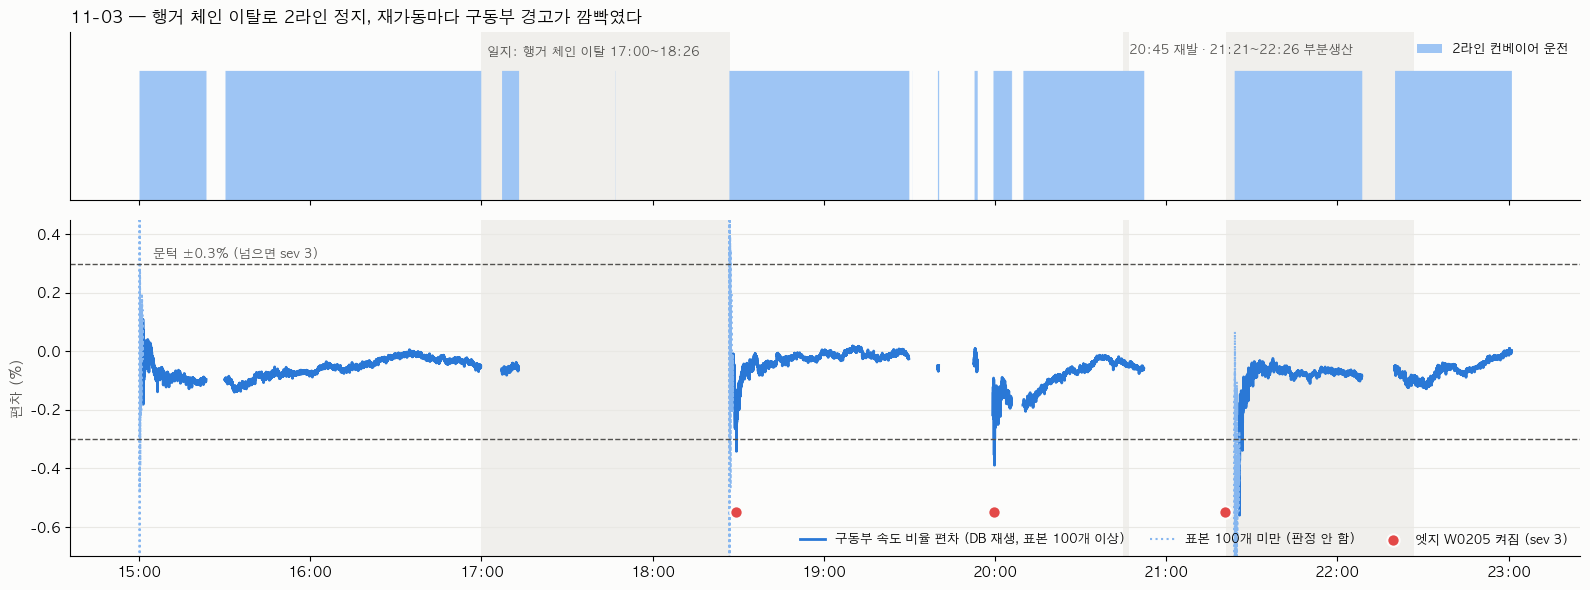

In [9]:
d3 = md_day("2026-11-03").loc["2026-11-03 15:00":"2026-11-03 23:00"]
run = d3.Conv_Run_Out.fillna(0)
on = ev[(ev.kind == "conveyor") & (ev.key == "drive") & ev.ts.between("2026-11-03 16:00", "2026-11-04 00:00")].sort_values("ts")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(16, 6), sharex=True, gridspec_kw=dict(height_ratios=[1, 2]), facecolor="#fcfcfb")
for ax in (a1, a2):
    ax.set_facecolor("#fcfcfb")
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for a, b in LOG["C05"]:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta("1min"), color="#f0efec", lw=0)
a1.fill_between(run.index, 0, run.values, step="post", color="#9ec5f4", lw=0, label="2라인 컨베이어 운전")
a1.set_yticks([]); a1.set_ylim(0, 1.3)
a1.text(pd.Timestamp("2026-11-03 17:02"), 1.12, "일지: 행거 체인 이탈 17:00~18:26", fontsize=9, color="#52514e")
a1.text(pd.Timestamp("2026-11-03 20:47"), 1.12, "20:45 재발 · 21:21~22:26 부분생산", fontsize=9, color="#52514e")
s = SP[SP.표본 >= 100]
SP.loc[SP.운전 == 0, "편차_pct"] = np.nan                     # 정지 중에는 판정 값이 그대로 남을 뿐이라 그리지 않는다
a2.plot(SP.index, SP.편차_pct.where(SP.표본 >= 100), color="#2a78d6", lw=2, label="구동부 속도 비율 편차 (DB 재생, 표본 100개 이상)")
a2.plot(SP.index, SP.편차_pct.where(SP.표본 < 100), color="#86b6ef", lw=1.5, ls=":", label="표본 100개 미만 (판정 안 함)")
for y in (-0.3, 0.3):
    a2.axhline(y, color="#52514e", lw=1, ls="--")
a2.text(pd.Timestamp("2026-11-03 15:05"), 0.32, "문턱 ±0.3% (넘으면 sev 3)", fontsize=9, color="#52514e")
act = on[on.active.astype(str) == "True"].ts
a2.scatter(act, np.full(len(act), -0.55), s=80, color="#e34948", ec="#fcfcfb", lw=1.5, zorder=4, label="엣지 W0205 켜짐 (sev 3)")
a2.set_ylim(-0.7, 0.45); a2.set_ylabel("편차 (%)", color="#52514e"); a2.grid(axis="y", color="#e9e8e4", lw=0.8)
a2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); a2.xaxis.set_major_locator(mdates.HourLocator())
h1, l1 = a1.get_legend_handles_labels(); a1.legend(loc="upper right", frameon=False, fontsize=9)
a2.legend(loc="lower right", frameon=False, fontsize=9, ncol=3)
a1.set_title("11-03 — 행거 체인 이탈로 2라인 정지, 재가동마다 구동부 경고가 깜빡였다", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIGS / "C05_drive_restart.png", dpi=110, facecolor="#fcfcfb")

- 정지가 30분 넘으면 속도 창이 빈다. 재가동 뒤 정속 표본이 100개(약 1분)를 넘으면 판정을 다시 시작하는데, 바로 그때 편차가 가장 크게 흔들린다.
- **DB 재생도 엣지와 같은 초에 문턱을 넘는다.** 18:29:23 −0.34%(엣지 켜짐 18:29:22), 19:59:50 −0.39%(엣지 19:59:49). 표본이 늘수록 −0.05% 안팎으로 돌아오고 경고도 꺼진다.
- 셋째(엣지 21:20:41)는 DB 운전 출력상 정지 중이라 맞지 않는다. DB 재생에서는 21:23:50 재가동 뒤 21:25:43에 −0.56%(표본 105개)로 넘는다.

## 6. 구동부 경고 전체 — 재가동 직후 표본이 적을 때 문턱을 넘는다

엣지 구동부 경고가 켜진 25번, 각각 직전 재가동에서 몇 분 뒤였나.

In [10]:
d = ev[(ev.kind == "conveyor") & (ev.key == "drive")].sort_values("ts")
on = d[d.active.astype(str) == "True"]
rows = []
for t in on.ts:
    try:
        r = md_day(t.normalize()).Conv_Run_Out.fillna(0)
    except Exception:
        rows.append((t, None)); continue
    up = r.index[r.diff() == 1]; prev = up[up <= t]
    rows.append((t, round((t - prev[-1]).total_seconds() / 60, 1) if len(prev) else None))
DR = pd.DataFrame(rows, columns=["켜짐", "직전 재가동 뒤(분)"])
DR["시각대"] = DR.켜짐.dt.strftime("%H:%M")
print(f"재가동 10분 안: {(DR['직전 재가동 뒤(분)'] <= 10).sum()} / {DR['직전 재가동 뒤(분)'].notna().sum()}")
DR

재가동 10분 안: 16 / 25


,켜짐,직전 재가동 뒤(분),시각대
0,2026-10-26 06:19:05.749,80.1,06:19
1,2026-10-26 11:27:39.637,1.2,11:27
2,2026-10-27 06:21:00.814,3.9,06:21
3,2026-10-28 19:51:05.606,4.8,19:51
4,2026-10-29 00:36:25.388,10.2,00:36
5,2026-10-29 06:21:55.954,2.0,06:21
6,2026-10-29 11:27:16.766,1.8,11:27
7,2026-10-29 11:35:17.216,9.8,11:35
8,2026-10-30 11:30:26.223,2.5,11:30
9,2026-10-30 19:52:59.660,4.0,19:52


25번 중 16번이 재가동 10분 안이다. 시각도 06:1x · 11:1x ~ 11:3x · 19:5x · 00:3x ~ 01:1x에 몰려 있다 — 아침 시작·점심·저녁·자정 휴식 직후다.
(10-26 06:19는 엣지 모델이 처음 켜진 순간이다. 11-03 21:20은 DB 운전 출력상 정지 중이라 직전 재가동이 70분 전으로 잡혔다. DB 재생에서는 21:23:50 재가동 2분 뒤 문턱을 넘는다(5절).)

재가동마다 "정속 표본이 N개 찼을 때의 편차"를 DB로 계산한다. 구동부 판정은 지금 표본 100개부터 한다.

In [11]:
res = []
for d in pd.date_range("2026-10-27", "2026-11-05"):
    raw = conv_day(d)
    r = raw[["R00040", "Hz_In_Conv", "Conv_Run_Out"]].ffill()
    t = r.index.to_series(); dt = t.diff().dt.total_seconds(); run = r.Conv_Run_Out.fillna(0)
    steady = (r.Hz_In_Conv.rolling(20).std() == 0) & (run.rolling(20).min() > 0) & (r.Hz_In_Conv > 0)   # 코어와 같은 정속 조건
    dR = r.R00040.diff(); ok = steady & (dt < 1) & (dR >= 0) & (dR < 50)
    for u in t[run.diff() == 1]:
        idx = ok.loc[u:u + pd.Timedelta("400s")]; idx = idx.index[idx]
        if len(idx) < 100:
            continue
        cs = pd.DataFrame({"dR": dR.loc[idx], "e": (dt * r.Hz_In_Conv / 10 * cr.K_SPEED).loc[idx]}).cumsum()
        for N in [100, 200, 400]:
            if len(idx) >= N:
                res.append(dict(N=N, 경과초=(idx[N - 1] - u).total_seconds(), 카운트=cs.dR.iloc[N - 1],
                                편차=(cs.dR.iloc[N - 1] / cs.e.iloc[N - 1] - 1) * 100))
RS = pd.DataFrame(res)
RS.groupby("N").agg(재가동수=("편차", "size"), 경과초=("경과초", "median"), 카운트=("카운트", "median"),
                   편차_표준편차=("편차", "std"), 문턱넘음=("편차", lambda s: (s.abs() > 0.3).mean())).round(3)

,재가동수,경과초,카운트,편차_표준편차,문턱넘음
N,,,,,
100,151,98.350,561.0,0.289,0.199
200,114,179.482,1117.5,0.251,0.149
400,93,331.425,2239.0,0.222,0.054


- 표본 100개(재가동 약 1분 40초 뒤, 약 560카운트)에서 편차의 표준편차가 0.29%다. **재가동의 20%가 그것만으로 문턱 0.3%를 넘는다.**
- 표본 400개(약 5분 반, 약 2,240카운트)까지 기다리면 5%로 준다. 재가동 뒤 30분 정속 평균은 −0.007%다 — 구동부는 멀쩡하다.
- 그래서 구동부 경고 대부분은 재가동 과도다 → 모델 수정 예정 C-06.

## 7. 결론

1. **C04 · C05 모두 모델 범위 밖(`OUT`)이다.** 행거 이송장치는 2라인 PLC 밖 설비라 신호가 하나도 들어오지 않는다. 대차 컨베이어와 다른 구동계다.
2. C04(10-31 체인 텐션 점검) 동안 2라인은 계속 돌았다. 데이터에 흔적이 없다.
3. C05(11-03 체인 이탈) 때 2라인은 일지와 같은 시각(17:13 ~ 18:26, 20:52 ~ 21:23)에 알람 없이 섰다. 작업자가 세운 것이다. 대차 컨베이어 속도 비율은 정상이다.
4. 그 시간대 W0205(구동부 속도)는 행거가 아니라 재가동 직후 깜빡임이다 → `FP`(재가동과도).
5. 구동부 경고 25번 중 16번이 재가동 10분 안이다. 판정 최소 표본(100개)이 문턱(0.3%)에 비해 작다 → 모델 수정 예정 C-06.
6. 행거 정지는 2라인에 "알람 없는 정지"로만 남는다. 행거를 보려면 행거 쪽 신호(구동 모터 전류·속도, 체인 이탈 L/S 등)가 필요하다.